In [1]:
#1 - imports, loading, missing values and split 60/20/20
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

df = pd.read_csv("/home/abdoulaye/Documents/Orange Digital center/Machine Learning Zoomcamp 2026/course_lead_scoring_2026.csv")

categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

y_train = df_train['converted'].values
y_val = df_val['converted'].values

print(len(df_train), len(df_val), len(df_test))

3000 1000 1000


In [ ]:
#AUC of each numerical variable on the training set
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])   # invert the variable
    print(col, round(auc, 3))

annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


In [ ]:
def train(df_tr, y_tr, C=1.0):
    dicts = df_tr[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[categorical + numerical].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

In [ ]:
Cell 4: Question 2 - AUC of the model on the validation set
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
print("Validation AUC:", round(roc_auc_score(y_val, y_pred), 3))

Validation AUC: 0.732


Q3 - precision/recall intersection at threshold: 0.63
Q4 - max F1 at threshold: 0.41


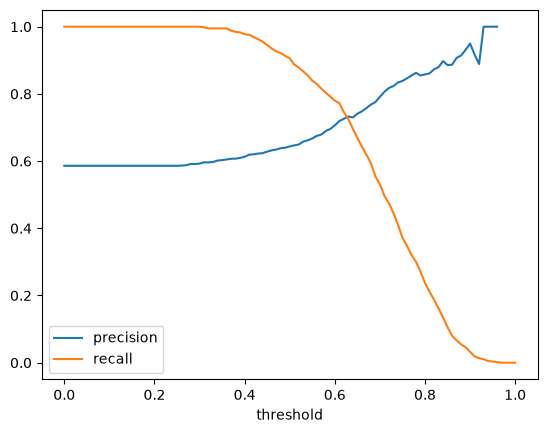

In [5]:
# Cell 5: Questions 3 and 4 - precision, recall and F1 for thresholds 0.0 to 1.0
thresholds = np.arange(0.0, 1.01, 0.01)
precisions, recalls, f1s = [], [], []

for t in thresholds:
    pred = (y_pred >= t)
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    r = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    f1 = 2 * p * r / (p + r) if (tp + fp) > 0 and (p + r) > 0 else np.nan

    precisions.append(p)
    recalls.append(r)
    f1s.append(f1)

precisions, recalls, f1s = np.array(precisions), np.array(recalls), np.array(f1s)

# Q3: threshold where the two curves intersect (ignore thresholds with no positive prediction)
diff = np.abs(precisions - recalls)
diff[np.isnan(diff)] = np.inf
print("Q3 - precision/recall intersection at threshold:", round(thresholds[np.argmin(diff)], 2))

# Q4: threshold where F1 is maximal
print("Q4 - max F1 at threshold:", round(thresholds[np.nanargmax(f1s)], 2))

plt.plot(thresholds, precisions, label='precision')
plt.plot(thresholds, recalls, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

In [6]:
# 5-fold cross-validation on df_full_train
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    dv_k, model_k = train(df_tr, df_tr['converted'].values)
    y_pred_k = predict(df_va, dv_k, model_k)
    scores.append(roc_auc_score(df_va['converted'].values, y_pred_k))

print("Scores:", [round(s, 3) for s in scores])
print("Std:", round(np.std(scores), 3))

Scores: [0.731, 0.73, 0.736, 0.741, 0.721]
Std: 0.007


In [7]:
# Cell 7: Question 6 - best C with 5-fold cross-validation
for C in [0.000001, 0.001, 1]:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        dv_k, model_k = train(df_tr, df_tr['converted'].values, C=C)
        y_pred_k = predict(df_va, dv_k, model_k)
        scores.append(roc_auc_score(df_va['converted'].values, y_pred_k))

    print(C, "| mean:", round(np.mean(scores), 3), "| std:", round(np.std(scores), 3))

1e-06 | mean: 0.617 | std: 0.019
0.001 | mean: 0.749 | std: 0.01
1 | mean: 0.732 | std: 0.007
